In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "synthetic_covid_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2400, 155)


,patient_id,age,sex,fever,cough,dyspnea,fatigue,headache,hypertension,diabetes,...,wavelet_014,wavelet_015,wavelet_016,wavelet_017,wavelet_018,wavelet_019,wavelet_020,ICU,mechanical_ventilation,death
0,P0001,57,0,0,1,0,1,0,0,0,...,-0.972052,-2.550070,-0.311566,0.868858,1.444569,-0.022637,0.180994,0,0,0
1,P0002,34,0,1,0,0,1,1,0,0,...,-0.875412,1.650275,1.353153,-0.679142,1.987041,0.120426,1.393416,0,0,0
2,P0003,65,0,1,1,0,0,0,1,1,...,0.509871,1.569078,0.068379,0.942279,0.389688,2.734910,-0.042336,1,1,1
3,P0004,68,0,0,1,0,0,1,0,0,...,-0.246149,-0.958745,0.140452,-1.069833,-0.288854,0.370459,0.482073,0,1,0
4,P0005,19,0,1,0,0,0,0,0,0,...,-1.255056,-1.511882,-1.616099,-0.182825,-0.631720,-2.478670,-0.721141,0,0,0


In [3]:
clinical_features = [
    "age",
    "sex",
    "hypertension",
    "diabetes",
    "cardiovascular_disease",
    "chronic_lung_disease",
    "immunosuppression",
    "smoking_history",
    "dyspnea",
    "fever",
    "cough",
    "respiratory_rate",
    "oxygen_saturation",
    "systolic_bp",
    "heart_rate"
]

lab_features = [
    "wbc",
    "lymphocyte",
    "neutrophil",
    "hemoglobin",
    "platelet",
    "crp",
    "ldh",
    "d_dimer",
    "ferritin",
    "ast",
    "alt",
    "creatinine",
    "urea",
    "albumin",
    "procalcitonin",
    "troponin",
    "il6"
]

target_features = [
    "ICU",
    "mechanical_ventilation",
    "death"
]

radiomics_features = [
    col for col in df.columns
    if col not in clinical_features + lab_features + target_features
]

print("Clinical:", len(clinical_features))
print("Labs:", len(lab_features))
print("Radiomics:", len(radiomics_features))

Clinical: 15
Labs: 17
Radiomics: 132


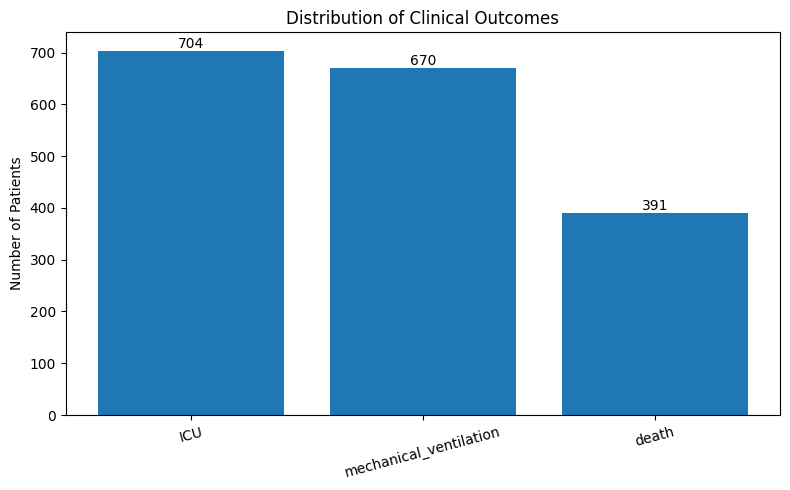

In [4]:
outcome_counts = df[target_features].sum()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    outcome_counts.index,
    outcome_counts.values
)

plt.title("Distribution of Clinical Outcomes")
plt.ylabel("Number of Patients")
plt.xticks(rotation=15)

for bar, value in zip(bars, outcome_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [5]:
outcome_percentages = (
    df[target_features].mean() * 100
).round(2)

display(
    outcome_percentages.to_frame("Positive Percentage")
)

,Positive Percentage
ICU,29.33
mechanical_ventilation,27.92
death,16.29


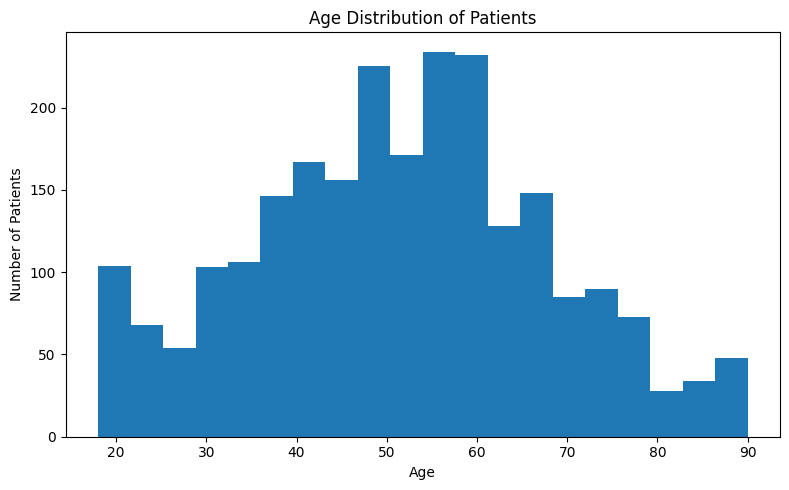

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["age"].dropna(),
    bins=20
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

/tmp/ipykernel_5240/3857574954.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


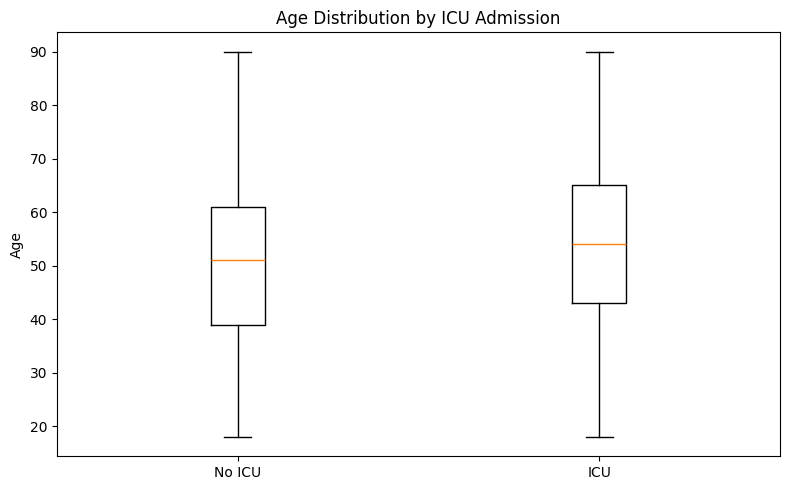

In [7]:
icu_0 = df.loc[df["ICU"] == 0, "age"]
icu_1 = df.loc[df["ICU"] == 1, "age"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [icu_0.dropna(), icu_1.dropna()],
    labels=["No ICU", "ICU"]
)

plt.title("Age Distribution by ICU Admission")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

/tmp/ipykernel_5240/1249067102.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


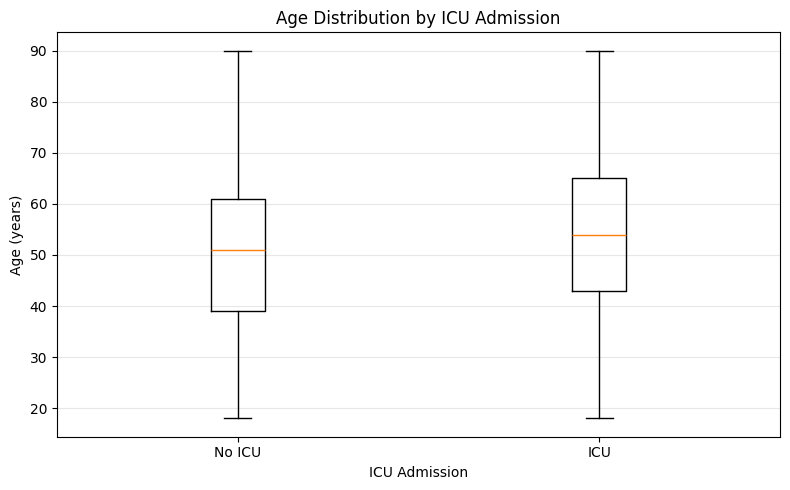

In [14]:

import pandas as pd
import matplotlib.pyplot as plt

# Compare age between patients with and without ICU admission
df["age"] = pd.to_numeric(df["age"], errors="coerce")

no_icu = df.loc[df["ICU"] == 0, "age"].dropna()
icu = df.loc[df["ICU"] == 1, "age"].dropna()

plt.figure(figsize=(8, 5))

plt.boxplot(
    [no_icu, icu],
    labels=["No ICU", "ICU"]
)

plt.title("Age Distribution by ICU Admission")
plt.xlabel("ICU Admission")
plt.ylabel("Age (years)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


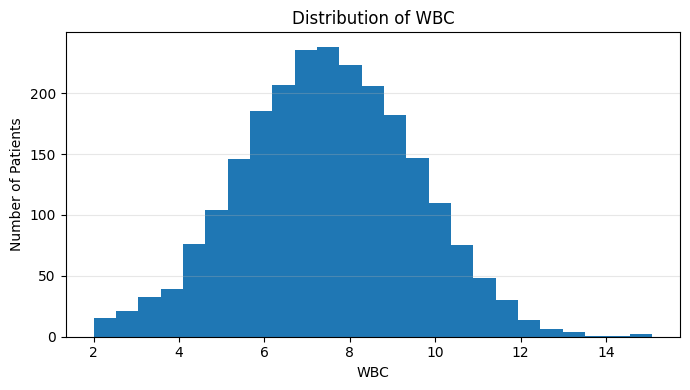

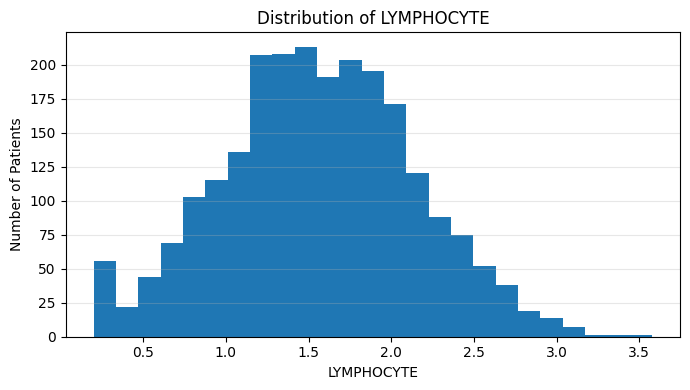

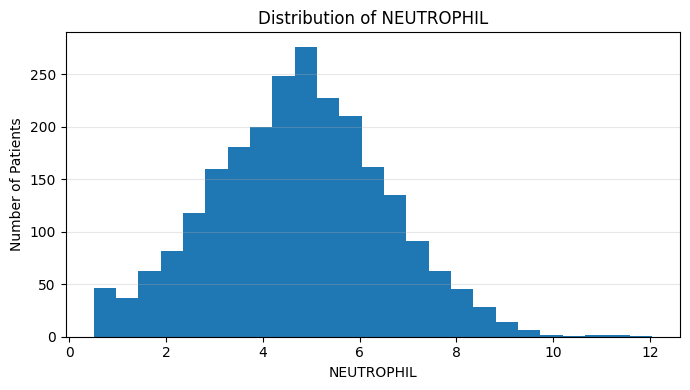

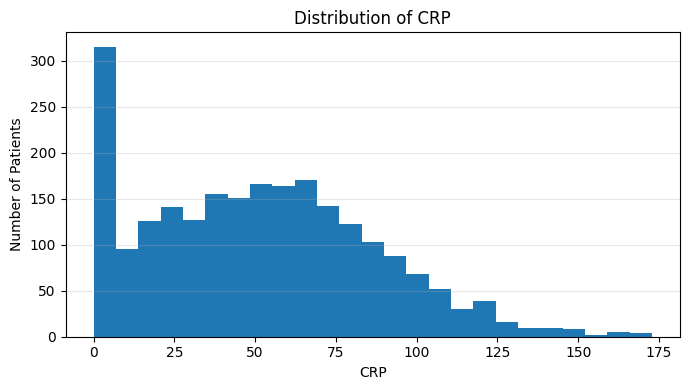

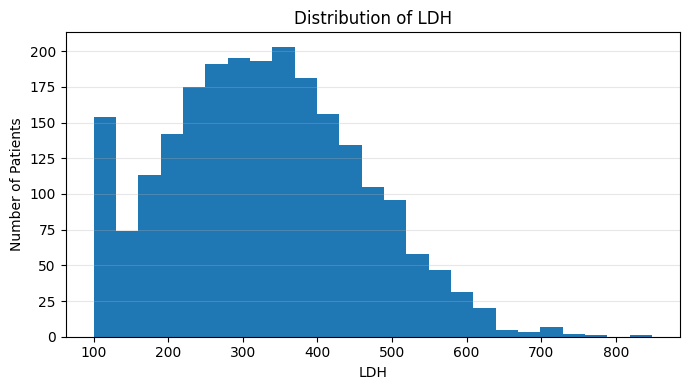

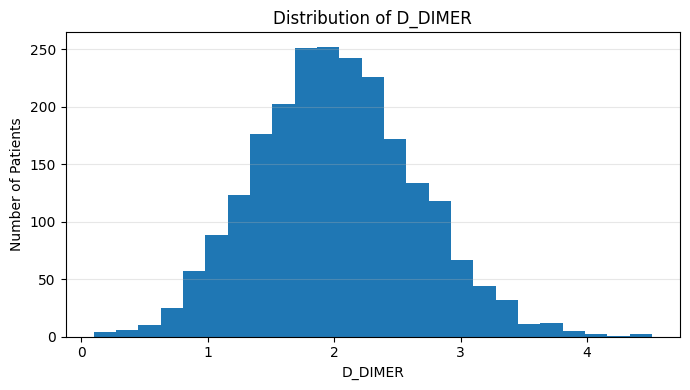

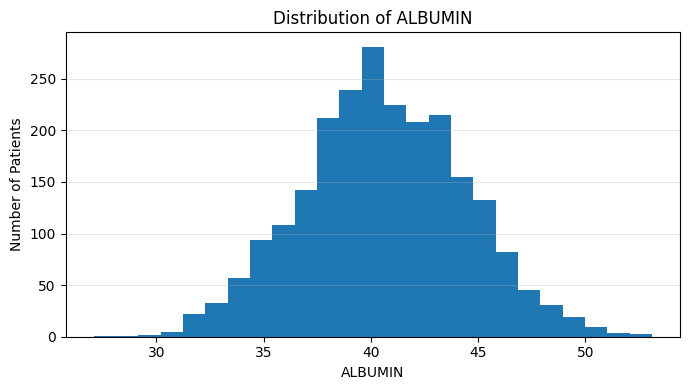

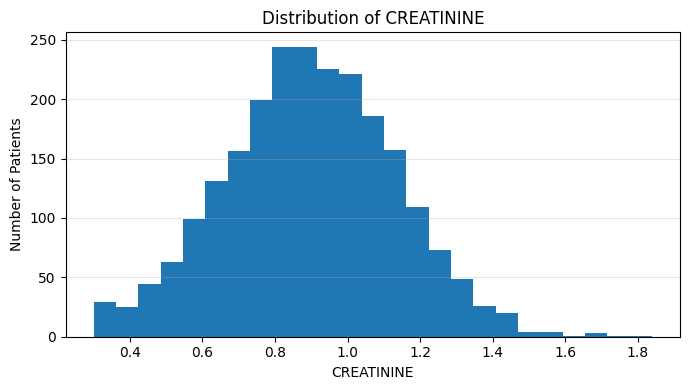

In [15]:

import pandas as pd
import matplotlib.pyplot as plt

important_labs = [
    "wbc",
    "lymphocyte",
    "neutrophil",
    "crp",
    "ldh",
    "d_dimer",
    "albumin",
    "creatinine"
]

for feature in important_labs:
    values = pd.to_numeric(
        df[feature], errors="coerce"
    ).dropna()

    if values.empty:
        print(f"Skipping {feature}: no valid numeric values.")
        continue

    plt.figure(figsize=(7, 4))

    plt.hist(values, bins=25)

    plt.title(f"Distribution of {feature.upper()}")
    plt.xlabel(feature.upper())
    plt.ylabel("Number of Patients")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


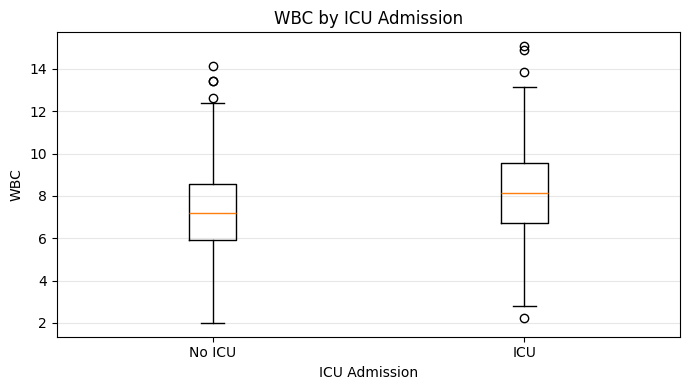

/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


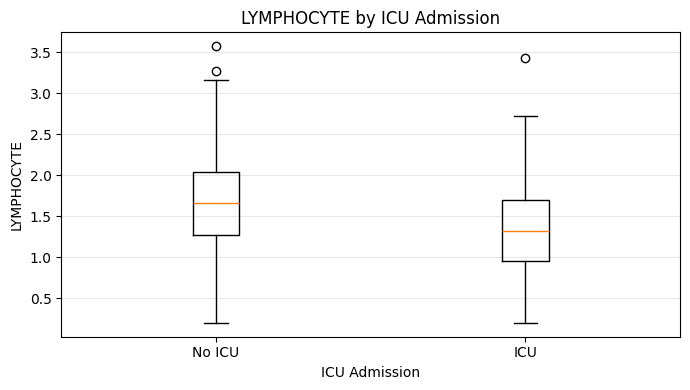

/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


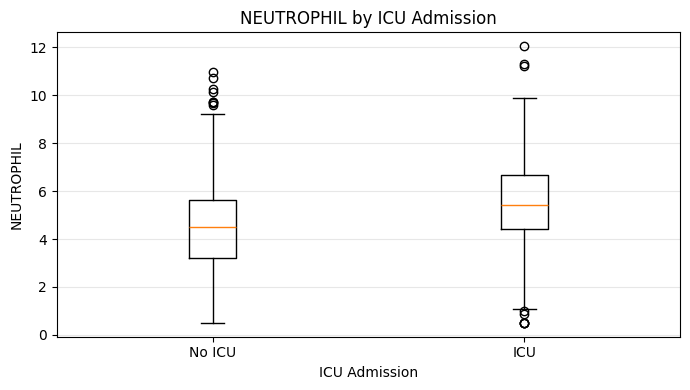

/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


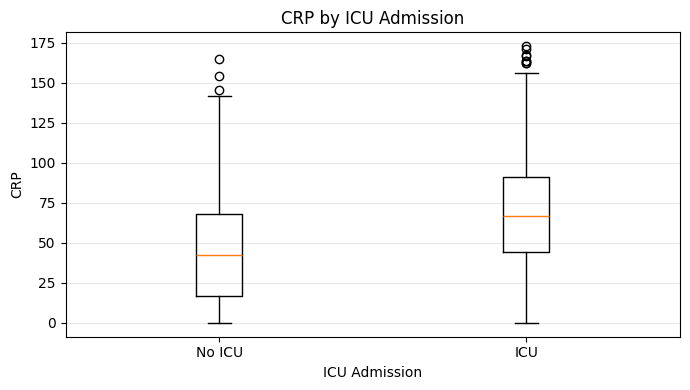

/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


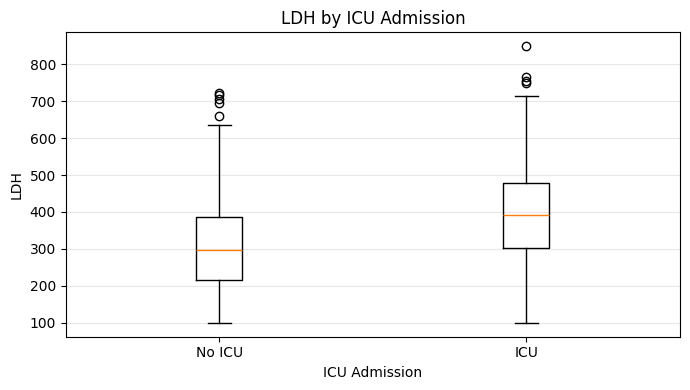

/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


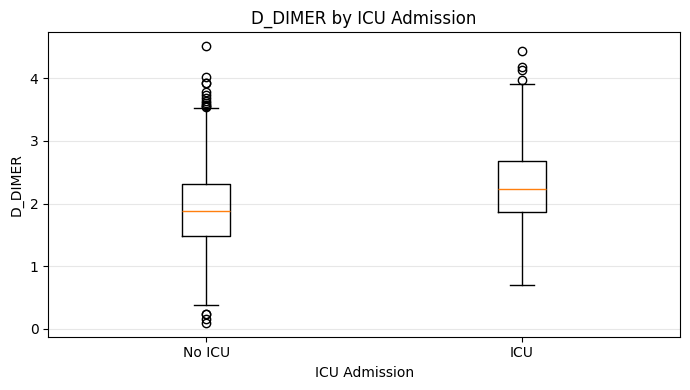

/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


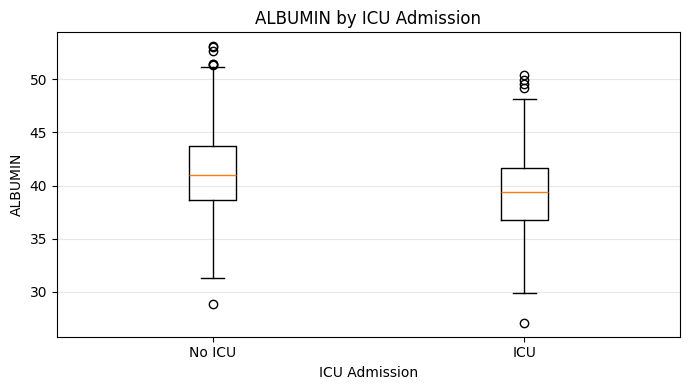

/tmp/ipykernel_5240/1865365208.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


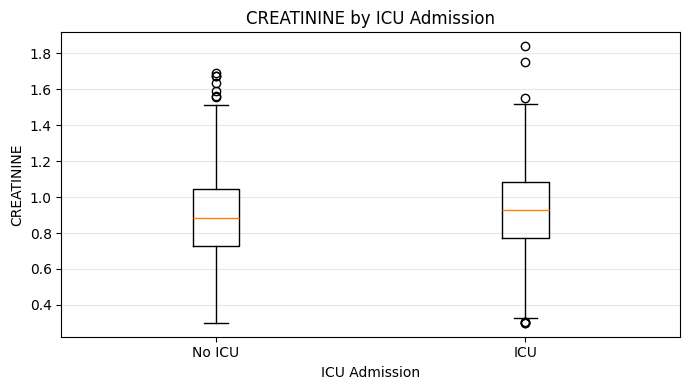

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

important_labs = [
    "wbc", "lymphocyte", "neutrophil", "crp",
    "ldh", "d_dimer", "albumin", "creatinine"
]

for feature in important_labs:
    no_icu = pd.to_numeric(
        df.loc[df["ICU"] == 0, feature],
        errors="coerce"
    ).dropna()

    icu = pd.to_numeric(
        df.loc[df["ICU"] == 1, feature],
        errors="coerce"
    ).dropna()

    if no_icu.empty or icu.empty:
        print(f"Skipping {feature}: insufficient numeric data.")
        continue

    plt.figure(figsize=(7, 4))

    plt.boxplot(
        [no_icu, icu],
        labels=["No ICU", "ICU"]
    )

    plt.title(f"{feature.upper()} by ICU Admission")
    plt.xlabel("ICU Admission")
    plt.ylabel(feature.upper())
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


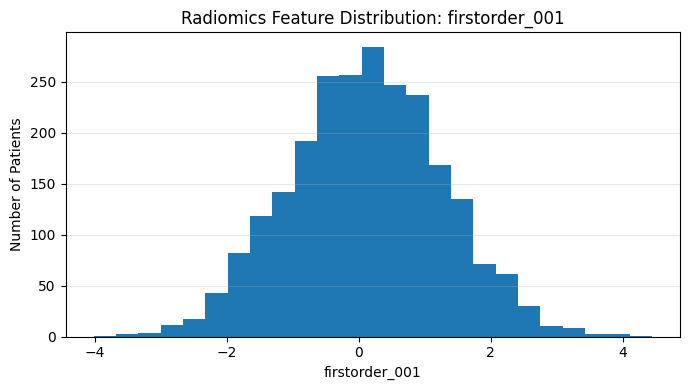

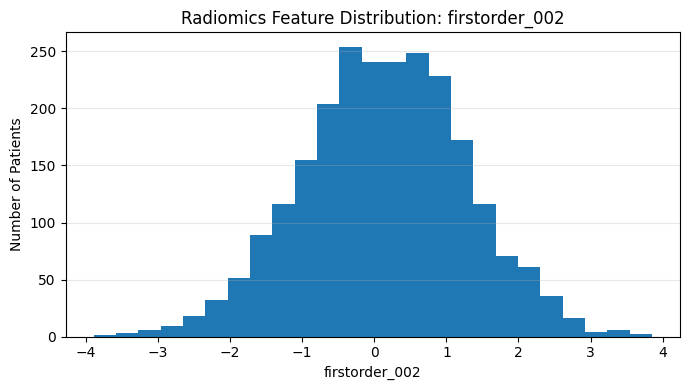

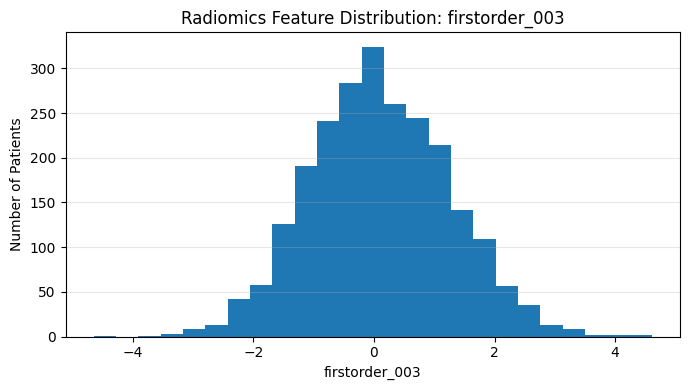

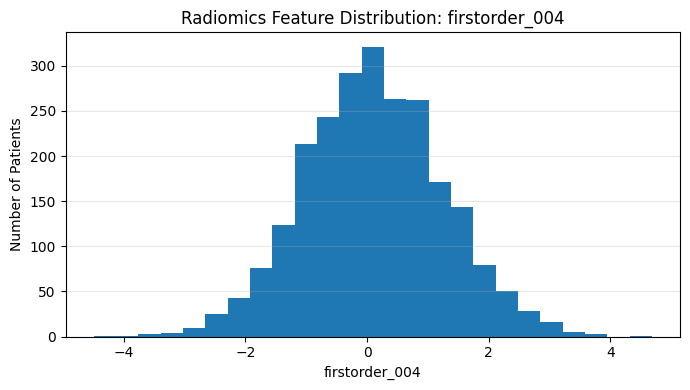

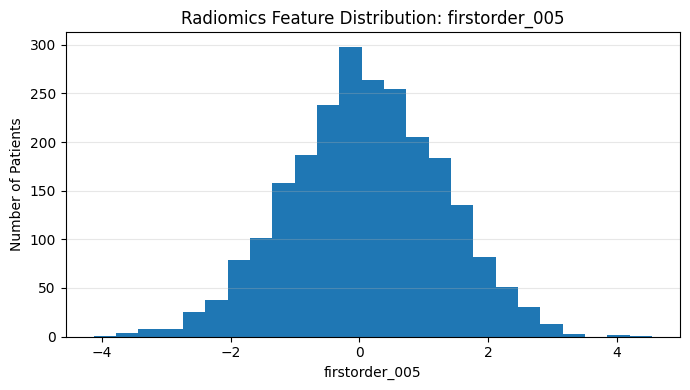

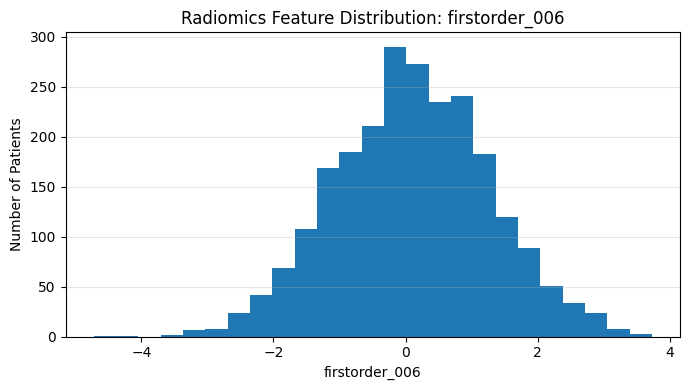

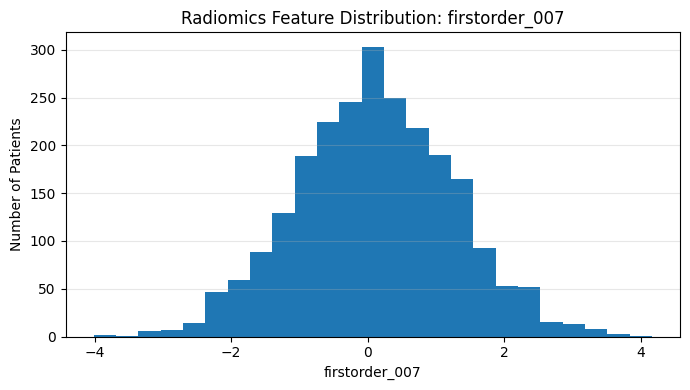

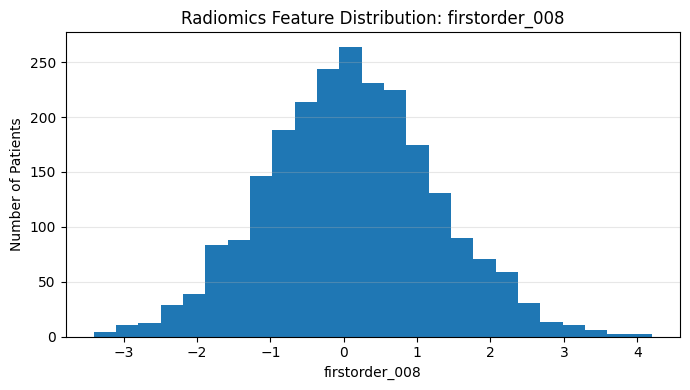

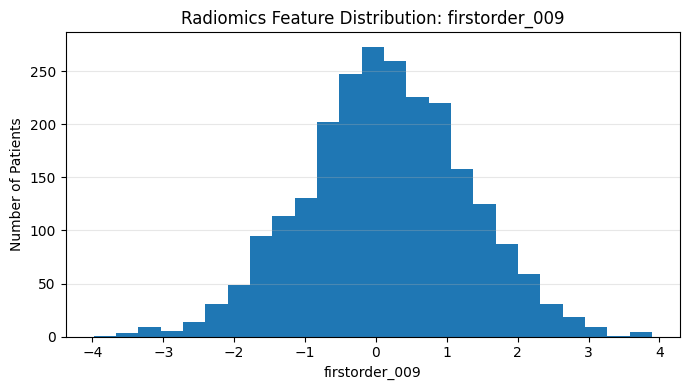

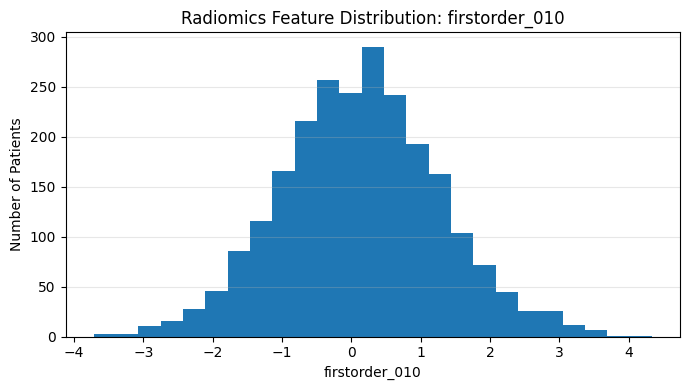

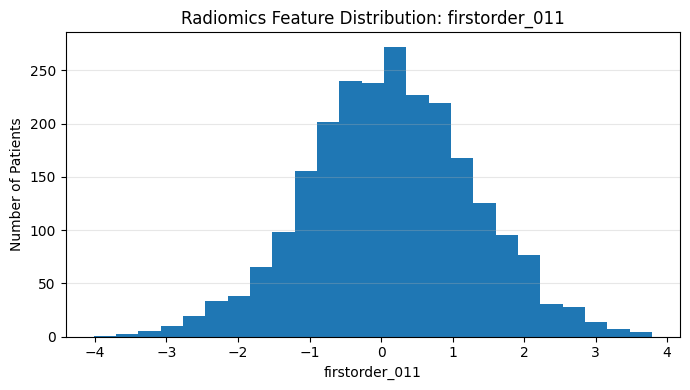

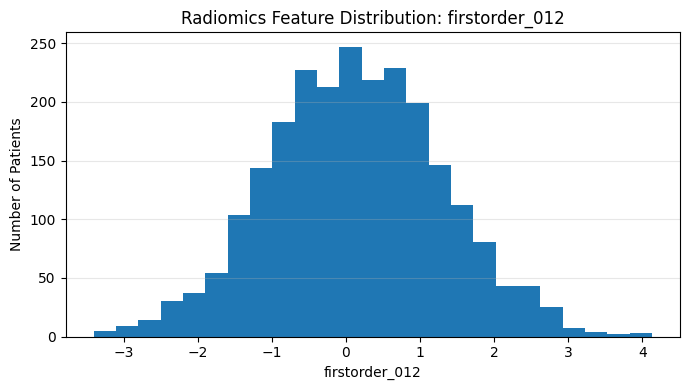

In [17]:

import matplotlib.pyplot as plt
import pandas as pd

radiomics_features = [
    col for col in df.columns
    if col.startswith((
        "firstorder_", "glcm_", "glszm_",
        "glrlm_", "ngtdm_", "wavelet_"
    ))
]

sample_radiomics = radiomics_features[:12]

for feature in sample_radiomics:
    values = pd.to_numeric(
        df[feature], errors="coerce"
    ).dropna()

    if values.empty:
        print(f"Skipping {feature}: no valid numeric values.")
        continue

    plt.figure(figsize=(7, 4))
    plt.hist(values, bins=25)

    plt.title(f"Radiomics Feature Distribution: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


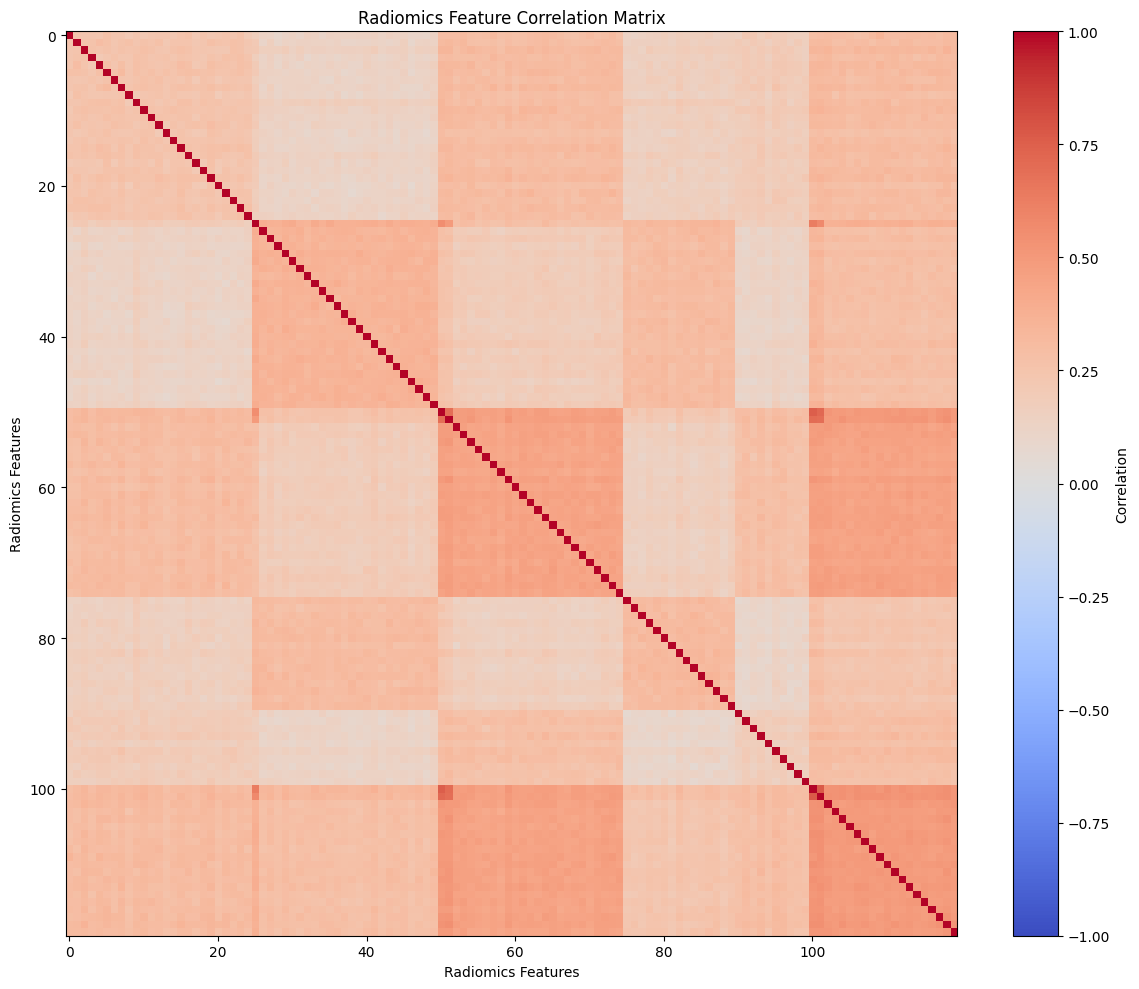

In [18]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

radiomics_data = df[radiomics_features].apply(
    pd.to_numeric, errors="coerce"
)

radiomics_corr = radiomics_data.corr()

plt.figure(figsize=(12, 10))

plt.imshow(
    radiomics_corr.to_numpy(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Correlation")
plt.title("Radiomics Feature Correlation Matrix")
plt.xlabel("Radiomics Features")
plt.ylabel("Radiomics Features")

plt.tight_layout()
plt.show()


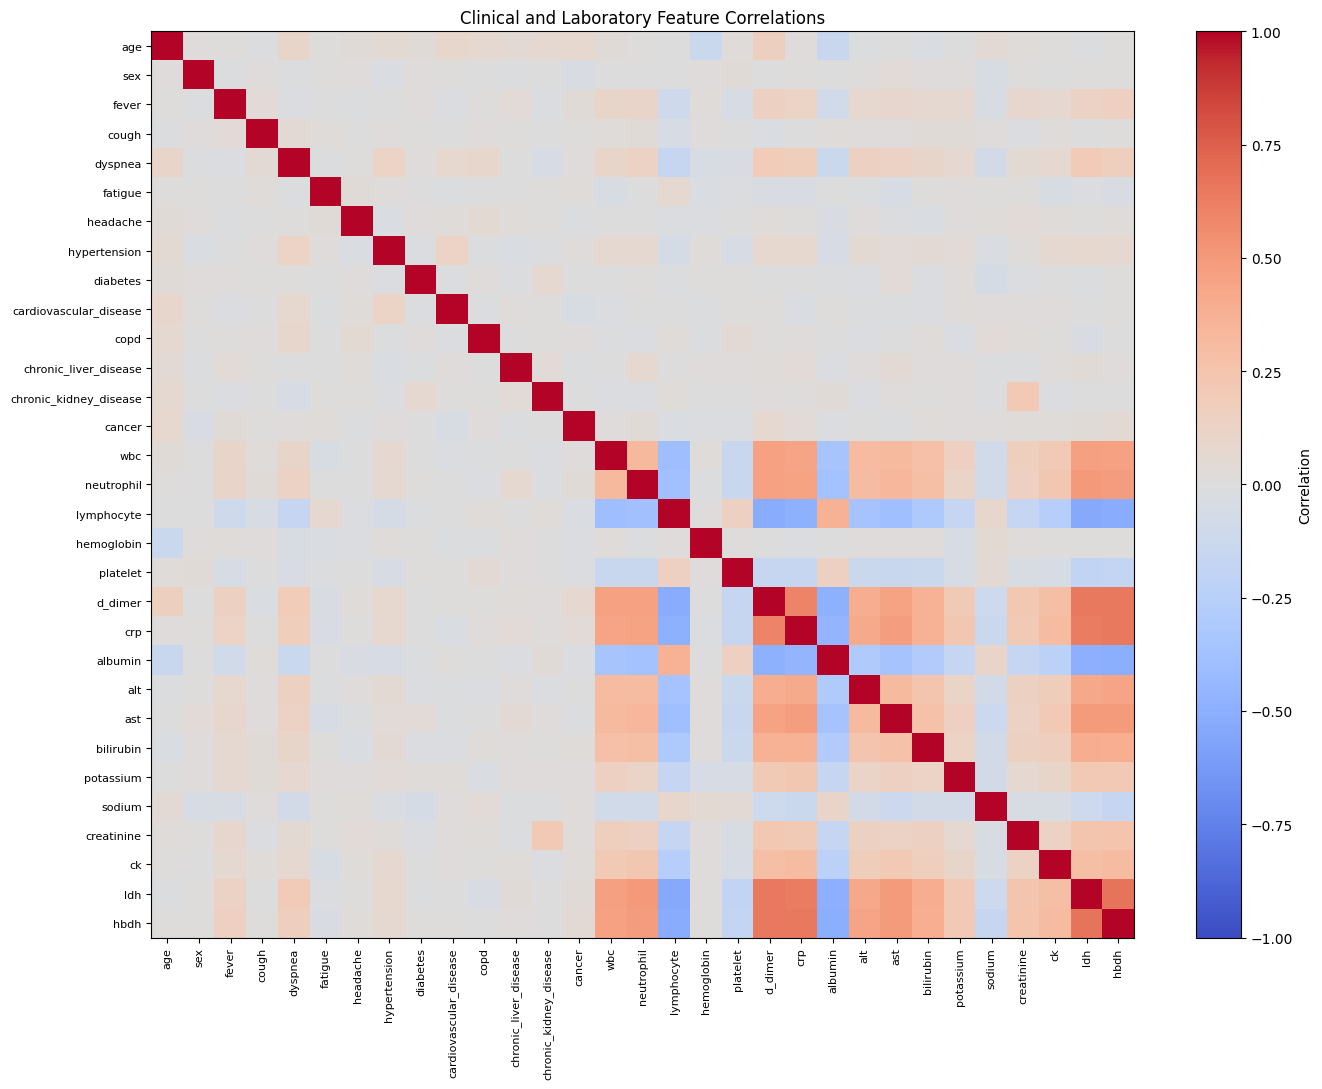

In [19]:

import matplotlib.pyplot as plt
import pandas as pd

clinical_features = [
    "age", "sex", "fever", "cough", "dyspnea",
    "fatigue", "headache", "hypertension", "diabetes",
    "cardiovascular_disease", "copd", "chronic_liver_disease",
    "chronic_kidney_disease", "cancer"
]

lab_features = [
    "wbc", "neutrophil", "lymphocyte", "hemoglobin",
    "platelet", "d_dimer", "crp", "albumin", "alt", "ast",
    "bilirubin", "potassium", "sodium", "creatinine",
    "ck", "ldh", "hbdh"
]

numeric_features = clinical_features + lab_features

clinical_lab_data = df[numeric_features].copy()

# Convert categorical values to numeric where possible.
# Encode sex only if it is stored as text.
if clinical_lab_data["sex"].dtype == "object":
    clinical_lab_data["sex"] = (
        clinical_lab_data["sex"]
        .astype("category")
        .cat.codes
    )

clinical_lab_data = clinical_lab_data.apply(
    pd.to_numeric, errors="coerce"
)

clinical_lab_corr = clinical_lab_data.corr()

plt.figure(figsize=(14, 11))

plt.imshow(
    clinical_lab_corr.to_numpy(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Correlation")
plt.xticks(
    range(len(numeric_features)),
    numeric_features,
    rotation=90,
    fontsize=8
)
plt.yticks(
    range(len(numeric_features)),
    numeric_features,
    fontsize=8
)

plt.title("Clinical and Laboratory Feature Correlations")
plt.tight_layout()
plt.show()


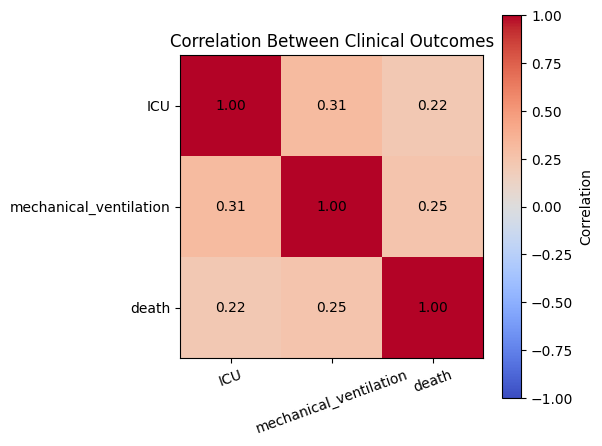

,ICU,mechanical_ventilation,death
ICU,1.000000,0.309007,0.216362
mechanical_ventilation,0.309007,1.000000,0.246102
death,0.216362,0.246102,1.000000


In [20]:

import matplotlib.pyplot as plt

target_features = [
    "ICU",
    "mechanical_ventilation",
    "death"
]

outcome_corr = df[target_features].corr()

plt.figure(figsize=(6, 5))

plt.imshow(
    outcome_corr.to_numpy(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(target_features)),
    target_features,
    rotation=20
)
plt.yticks(
    range(len(target_features)),
    target_features
)

# Display correlation values inside the plot
for i in range(len(target_features)):
    for j in range(len(target_features)):
        plt.text(
            j, i,
            f"{outcome_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Between Clinical Outcomes")
plt.tight_layout()
plt.show()

display(outcome_corr)


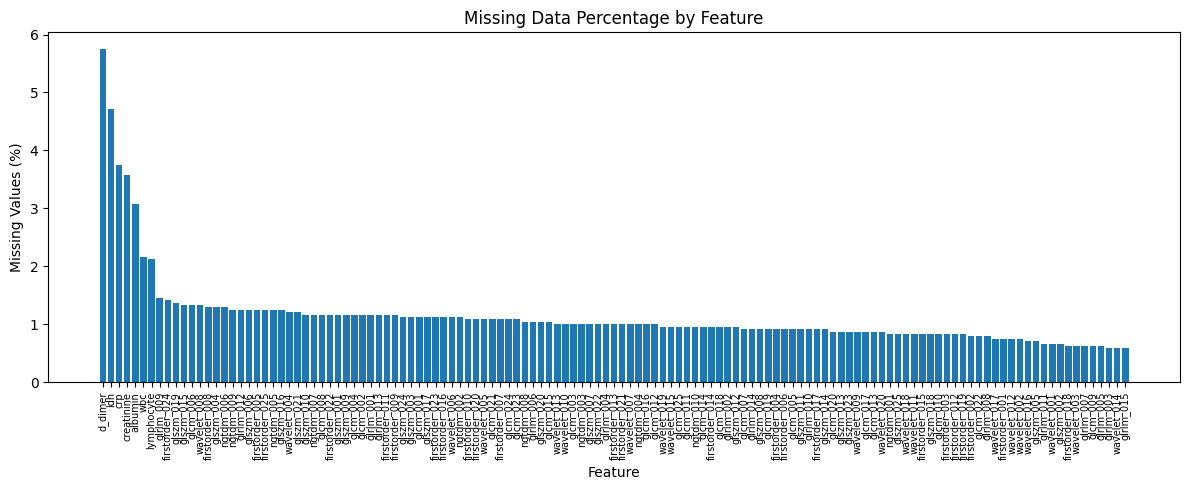

,Missing Percentage
d_dimer,5.750000
ldh,4.708333
crp,3.750000
creatinine,3.583333
albumin,3.083333
...,...
glcm_009,0.625000
glrlm_005,0.625000
glrlm_003,0.583333
wavelet_014,0.583333


In [21]:

import matplotlib.pyplot as plt
import pandas as pd

missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[
    missing_percentage > 0
]

if missing_percentage.empty:
    print("No missing values found in the dataset.")
else:
    plt.figure(figsize=(12, 5))

    plt.bar(
        missing_percentage.index,
        missing_percentage.values
    )

    plt.title("Missing Data Percentage by Feature")
    plt.xlabel("Feature")
    plt.ylabel("Missing Values (%)")
    plt.xticks(rotation=90, fontsize=7)

    plt.tight_layout()
    plt.show()

    display(
        missing_percentage.to_frame(
            name="Missing Percentage"
        )
    )


In [22]:

import pandas as pd

clinical_features = [
    "age", "sex", "fever", "cough", "dyspnea",
    "fatigue", "headache", "hypertension", "diabetes",
    "cardiovascular_disease", "copd", "chronic_liver_disease",
    "chronic_kidney_disease", "cancer"
]

lab_features = [
    "wbc", "neutrophil", "lymphocyte", "hemoglobin",
    "platelet", "d_dimer", "crp", "albumin", "alt", "ast",
    "bilirubin", "potassium", "sodium", "creatinine",
    "ck", "ldh", "hbdh"
]

target_features = [
    "ICU", "mechanical_ventilation", "death"
]

radiomics_features = [
    col for col in df.columns
    if col.startswith((
        "firstorder_", "glcm_", "glszm_",
        "glrlm_", "ngtdm_", "wavelet_"
    ))
]

eda_summary = pd.DataFrame({
    "Metric": [
        "Number of patients",
        "Total columns",
        "Clinical features",
        "Laboratory features",
        "Radiomics features",
        "ICU positive cases",
        "ICU positive (%)",
        "Mechanical ventilation cases",
        "Mechanical ventilation positive (%)",
        "Death cases",
        "Death positive (%)",
        "Total missing cells",
        "Duplicate rows"
    ],
    "Value": [
        len(df),
        len(df.columns),
        len(clinical_features),
        len(lab_features),
        len(radiomics_features),
        int(df["ICU"].sum()),
        round(df["ICU"].mean() * 100, 2),
        int(df["mechanical_ventilation"].sum()),
        round(df["mechanical_ventilation"].mean() * 100, 2),
        int(df["death"].sum()),
        round(df["death"].mean() * 100, 2),
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum())
    ]
})

display(eda_summary)


,Metric,Value
0,Number of patients,2400.00
1,Total columns,155.00
2,Clinical features,14.00
3,Laboratory features,17.00
4,Radiomics features,120.00
5,ICU positive cases,704.00
6,ICU positive (%),29.33
7,Mechanical ventilation cases,670.00
8,Mechanical ventilation positive (%),27.92
9,Death cases,391.00
